In [73]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image


In [74]:
DATA_PATH = Path.cwd().parent / "data"
BARCELONA_DATA_PATH = "PBC_dataset_normal_DIB"
MUNICH_DATA_PATH = "PKG-AML-Cytomorphology_LMU"
ABBREVIATIONS = DATA_PATH / MUNICH_DATA_PATH / "abbreviations.txt"


In [75]:
full_df = pd.read_csv(DATA_PATH / "blood_cells_data_with_histograms.csv")
full_norm_df = pd.read_csv(DATA_PATH / "blood_cells_data_with_histograms_norm.csv")
hists = pd.read_csv(DATA_PATH / "blood_cells_histograms.csv")
hists_norm = pd.read_csv(DATA_PATH / "blood_cells_histograms_norm.csv")

In [ ]:
data = {
    "dataset": [],
    "path": [],
    "original_type": [],
    "format": [],
    "size_x": [],
    "size_y": [],
    "mode": [],
}
for root, dirs, files in os.walk(DATA_PATH):
    for file in [f for f in files if (f.endswith((".tiff", ".jpg"))) and not f.startswith(".")]:
        file_path = os.path.join(root, file)
        img = Image.open(file_path)
        data["path"].append(file_path)
        data["dataset"].append("BARCELONA" if BARCELONA_DATA_PATH in file_path else "MUNICH")
        data["original_type"].append(os.path.basename(os.path.normpath(root)))
        data["format"].append(img.format)
        data["size_x"].append(img.size[0])
        data["size_y"].append(img.size[1])
        data["mode"].append(img.mode)


In [6]:
df = pd.DataFrame(data)
df.head()

,dataset,path,original_type,format,size_x,size_y,mode
0,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA
1,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA
2,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA
3,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA
4,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA


In [10]:
df.original_type.unique()

<StringArray>
[         'KSC',          'MYO',          'NGB',          'MON',
          'PMO',          'MMZ',          'EBO',          'MYB',
          'NGS',          'BAS',          'MOB',          'LYA',
          'LYT',          'EOS',          'PMB',     'basophil',
   'neutrophil',           'ig',     'monocyte',   'eosinophil',
 'erythroblast',   'lymphocyte',     'platelet']
Length: 23, dtype: str

In [16]:
with open(ABBREVIATIONS) as f:
    lines = f.readlines()
abbr_df = pd.DataFrame(
    [line.strip().split(" ") for line in lines[2:-3]], columns=["Abbreviation", "Name", "Details"]
).set_index("Abbreviation")
abbr_df.fillna("", inplace=True)

,Name,Details
Abbreviation,,
BAS,Basophil,
EBO,Erythroblast,
EOS,Eosinophil,
KSC,Smudge,cell
LYA,Lymphocyte,(atypical)
LYT,Lymphocyte,(typical)
MMZ,Metamyelocyte,
MOB,Monoblast,
MON,Monocyte,


In [26]:
(abbr_df.Name + " " + abbr_df.Details).values

<StringArray>
[              'Basophil ',           'Erythroblast ',
             'Eosinophil ',             'Smudge cell',
   'Lymphocyte (atypical)',    'Lymphocyte (typical)',
          'Metamyelocyte ',              'Monoblast ',
               'Monocyte ',              'Myelocyte ',
             'Myeloblast ',       'Neutrophil (band)',
  'Neutrophil (segmented)', 'Promyelocyte (bilobled)',
           'Promyelocyte ']
Length: 15, dtype: str

In [ ]:
type_dict = {
    "MYB": "ig",
    "MMZ": "ig",
    "PMO": "ig",
    "PMB": "ig",  # ou sa propre catégorie ?
    "MYO": "myeloblast",
    "MOB": "monoblast",
    "KSC": "smudge",
}

In [ ]:
def map_type(original_type: str):
    if original_type in type_dict:
        return type_dict[original_type]
    if original_type in abbr_df.index:
        return abbr_df.loc[original_type].Name.lower()
    return original_type


df["type"] = df.original_type.map(map_type)

In [24]:
df.head()

,dataset,path,original_type,type
0,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,smudge
1,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,smudge
2,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,smudge
3,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,smudge
4,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,smudge


In [25]:
df.type.value_counts()

type
neutrophil      11923
lymphocyte       5162
eosinophil       3541
myeloblast       3268
monocyte         3209
ig               3040
platelet         2348
erythroblast     1629
basophil         1297
monoblast          26
smudge             15
Name: count, dtype: int64

In [28]:
(df.type.value_counts(normalize=True) * 100).round(2).astype(str) + "%"

type
neutrophil      33.63%
lymphocyte      14.56%
eosinophil       9.99%
myeloblast       9.22%
monocyte         9.05%
ig               8.57%
platelet         6.62%
erythroblast     4.59%
basophil         3.66%
monoblast        0.07%
smudge           0.04%
Name: proportion, dtype: str

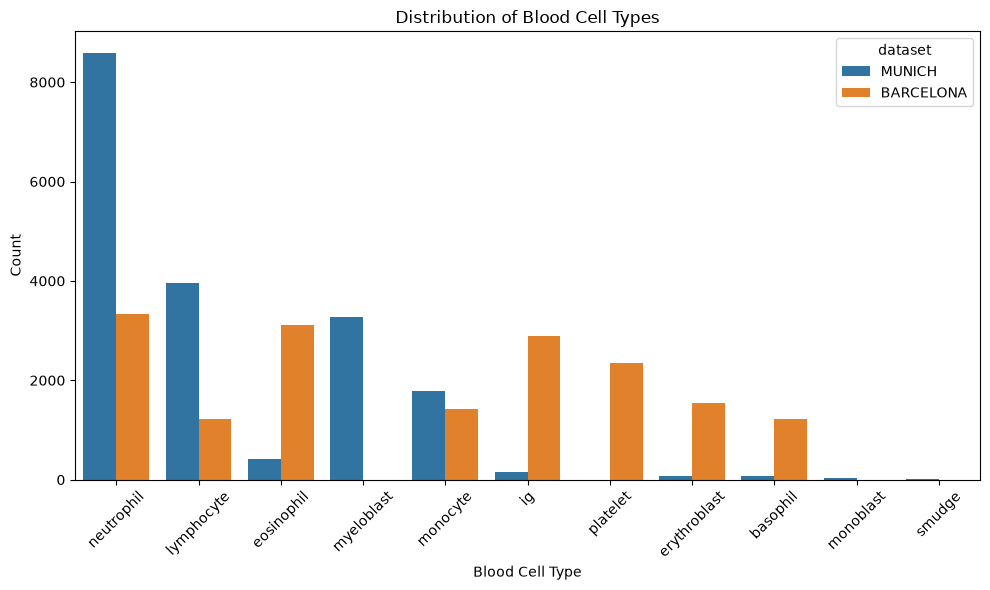

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="type", hue="dataset", order=df["type"].value_counts().index)
plt.title("Distribution of Blood Cell Types")
plt.xlabel("Blood Cell Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
barcelona_img_path = df[df.dataset == "BARCELONA"].iloc[0].path
munich_img_path = df[df.dataset == "MUNICH"].iloc[0].path

In [39]:
from PIL import Image

img_barcelona = Image.open(barcelona_img_path)
img_munich = Image.open(munich_img_path)

In [40]:
print(img_barcelona.format, img_barcelona.size, img_barcelona.mode)
print(img_munich.format, img_munich.size, img_munich.mode)

JPEG (360, 363) RGB
TIFF (400, 400) RGBA


In [44]:
np.array(img_munich.getdata()).shape

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_74111/804300651.py:1: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  np.array(img_munich.getdata()).shape


(160000, 4)

In [57]:
print(df[df.dataset == "BARCELONA"]["size_x"].value_counts())
print(df[df.dataset == "BARCELONA"]["size_y"].value_counts())
print(
    (
        df[df.dataset == "BARCELONA"]["size_x"] * df[df.dataset == "BARCELONA"]["size_y"]
    ).value_counts()
)
print(df[df.dataset == "MUNICH"]["size_x"].value_counts())
print(df[df.dataset == "MUNICH"]["size_y"].value_counts())

size_x
360    16839
366      250
361        1
359        1
362        1
Name: count, dtype: int64
size_y
363    16639
369      250
360      201
361        2
Name: count, dtype: int64
130680    16639
135054      250
129600      198
129960        3
129240        1
130320        1
Name: count, dtype: int64
size_x
400    18365
Name: count, dtype: int64
size_y
400    18365
Name: count, dtype: int64


In [63]:
img_barcelona.getcolors(160000)

[(4, (63, 25, 128)),
 (3, (62, 25, 128)),
 (1, (72, 8, 128)),
 (1, (62, 8, 128)),
 (1, (65, 25, 160)),
 (1, (61, 10, 128)),
 (2, (67, 14, 128)),
 (1, (72, 29, 160)),
 (1, (102, 51, 128)),
 (1, (103, 50, 128)),
 (1, (145, 119, 128)),
 (1, (95, 51, 128)),
 (2, (55, 17, 128)),
 (1, (63, 16, 128)),
 (2, (56, 16, 128)),
 (3, (195, 154, 168)),
 (1, (54, 21, 128)),
 (1, (60, 21, 128)),
 (1, (59, 21, 160)),
 (1, (73, 20, 128)),
 (1, (63, 20, 128)),
 (1, (62, 20, 128)),
 (1, (49, 20, 128)),
 (1, (56, 20, 128)),
 (7, (64, 21, 128)),
 (1, (88, 43, 128)),
 (2, (65, 24, 128)),
 (2, (85, 41, 128)),
 (1, (153, 100, 128)),
 (3, (63, 28, 128)),
 (5, (64, 28, 128)),
 (2, (88, 34, 128)),
 (1, (69, 34, 128)),
 (1, (81, 34, 128)),
 (1, (74, 35, 128)),
 (2, (73, 32, 128)),
 (1, (255, 223, 193)),
 (1, (77, 33, 128)),
 (2, (78, 33, 128)),
 (2, (83, 33, 128)),
 (1, (255, 219, 193)),
 (1, (96, 42, 128)),
 (4, (80, 40, 128)),
 (1, (134, 86, 128)),
 (2, (246, 207, 192)),
 (8, (240, 207, 192)),
 (7, (239, 207, 192

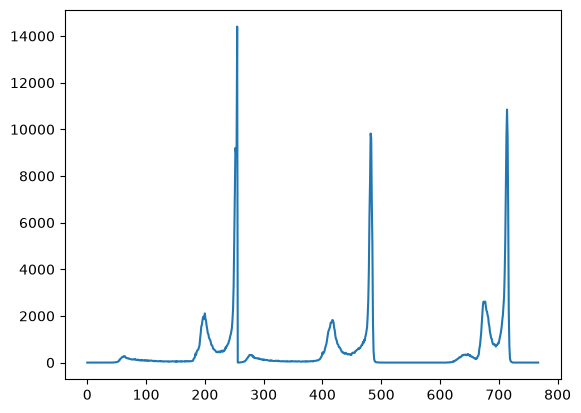

In [68]:
plt.plot(img_barcelona.histogram());

In [ ]:
colors = np.zeros((len(df), 768))
gray = np.zeros((len(df), 256))

for i, row in enumerate(df.itertuples()):
    img = Image.open(row.path)
    if img.mode != "RGB":
        img = img.convert("RGB")
    colors[i] = np.array(img.histogram())
    gray[i] = np.array(img.convert("L").histogram())


In [76]:
colors_df = pd.DataFrame(
    colors,
    columns=[f"R{i}" for i in range(256)]
    + [f"G{i}" for i in range(256)]
    + [f"B{i}" for i in range(256)],
)
gray_df = pd.DataFrame(gray, columns=[f"Gray{i}" for i in range(256)])
full_df = pd.concat([df, colors_df, gray_df], axis=1)
full_df.head()

,dataset,path,original_type,format,size_x,size_y,mode,type,R0,R1,...,Gray246,Gray247,Gray248,Gray249,Gray250,Gray251,Gray252,Gray253,Gray254,Gray255
0,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA,smudge,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA,smudge,0.0,0.0,...,1073.0,919.0,723.0,543.0,377.0,259.0,159.0,66.0,11.0,0.0
2,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA,smudge,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA,smudge,0.0,0.0,...,1760.0,2236.0,2725.0,3446.0,4987.0,7832.0,14927.0,25239.0,17756.0,1729.0
4,MUNICH,/Users/romain/Projects/Liora/Projet/jul26_bds_...,KSC,TIFF,400,400,RGBA,smudge,0.0,0.0,...,2506.0,912.0,301.0,90.0,36.0,12.0,5.0,0.0,0.0,0.0


In [77]:
full_df.to_csv(DATA_PATH / "blood_cells_data_with_histograms.csv", index=False)

In [ ]:
hists = (
    full_df.drop(["path", "original_type", "format", "mode", "size_x", "size_y"], axis=1)
    .groupby(["dataset", "type"])
    .mean()
)
hists.to_csv(DATA_PATH / "blood_cells_histograms.csv")

In [86]:
hists.xs("basophil", axis=0, level=1, drop_level=False)

,,R0,R1,R2,R3,R4,R5,R6,R7,R8,R9,...,Gray246,Gray247,Gray248,Gray249,Gray250,Gray251,Gray252,Gray253,Gray254,Gray255
dataset,type,,,,,,,,,,,,,,,,,,,,,
BARCELONA,basophil,0.004105,0.001642,0.004926,0.002463,0.005747,0.005747,0.004926,0.005747,0.013957,0.018883,...,0.144499,0.069787,0.027094,0.013957,0.003284,0.000000,0.000000,0.000000,0.000000,0.000000
MUNICH,basophil,913.367089,63.632911,49.544304,38.759494,26.518987,21.936709,19.696203,18.075949,17.734177,17.253165,...,1248.101266,899.050633,674.696203,507.455696,439.810127,393.025316,395.278481,470.797468,908.253165,652.987342


In [87]:
hists.head(10)

R0         R1         R2         R3  \
dataset   type                                                        
BARCELONA basophil        0.004105   0.001642   0.004926   0.002463   
          eosinophil      0.000321   0.000321   0.000000   0.000000   
          erythroblast    0.012895   0.010316   0.021277   0.018698   
          ig              0.001382   0.000345   0.000345   0.000691   
          lymphocyte      0.000000   0.000000   0.000000   0.000000   
          monocyte        0.000000   0.000000   0.000000   0.000000   
          neutrophil      0.000000   0.000000   0.000000   0.000300   
          platelet        0.000000   0.000000   0.000000   0.000000   
MUNICH    basophil      913.367089  63.632911  49.544304  38.759494   
          eosinophil    367.775943   9.214623   8.247642   6.490566   

                               R4         R5         R6         R7         R8  \
dataset   type                                                                  
BARCELONA basophil       0.005747   0.005747   0.004926   0.005747   0.013957   
          eosinophil     0.000321   0.001604   0.000962   0.001925   0.001283   
          erythroblast   0.015474   0.038685   0.030303   0.070922   0.069632   
          ig             0.001727   0.003800   0.002418   0.003454   0.004836   
          lymphocyte     0.000000   0.000000   0.000000   0.000000   0.000000   
          monocyte       0.000000   0.000000   0.000000   0.000000   0.000000   
          neutrophil     0.000300   0.000601   0.000601   0.001202   0.001802   
          platelet       0.000000   0.000000   0.000000   0.000000   0.000000   
MUNICH    basophil      26.518987  21.936709  19.696203  18.075949  17.734177   
          eosinophil     5.209906   4.308962   3.808962   3.830189   3.877358   

                               R9  ...      Gray246     Gray247     Gray248  \
dataset   type                     ...                                        
BARCELONA basophil       0.018883  ...     0.144499    0.069787    0.027094   
          eosinophil     0.003529  ...     0.076676    0.032724    0.010266   
          erythroblast   0.087041  ...     0.010961    0.001934    0.000000   
          ig             0.010363  ...     0.060104    0.028670    0.009326   
          lymphocyte     0.000000  ...     0.009885    0.009885    0.001647   
          monocyte       0.000000  ...     0.018310    0.007746    0.003521   
          neutrophil     0.002103  ...     0.010814    0.004806    0.002704   
          platelet       0.000000  ...     0.005537    0.000852    0.002981   
MUNICH    basophil      17.253165  ...  1248.101266  899.050633  674.696203   
          eosinophil     3.754717  ...  1199.735849  957.476415  828.688679   

                           Gray249     Gray250     Gray251     Gray252  \
dataset   type                                                           
BARCELONA basophil        0.013957    0.003284    0.000000    0.000000   
          eosinophil      0.002887    0.001925    0.000321    0.000000   
          erythroblast    0.000645    0.000000    0.000645    0.000000   
          ig              0.004836    0.013817    0.042832    0.021071   
          lymphocyte      0.003295    0.000000    0.000000    0.000000   
          monocyte        0.003521    0.000704    0.000000    0.000000   
          neutrophil      0.003304    0.000601    0.000300    0.000000   
          platelet        0.000852    0.000426    0.000000    0.000000   
MUNICH    basophil      507.455696  439.810127  393.025316  395.278481   
          eosinophil    702.794811  609.724057  532.205189  569.054245   

                           Gray253     Gray254     Gray255  
dataset   type                                              
BARCELONA basophil        0.000000    0.000000    0.000000  
          eosinophil      0.000000    0.000000    0.000000  
          erythroblast    0.000000    0.000000    0.000000  
          ig              0.131952    0.037997    0.000000  
  

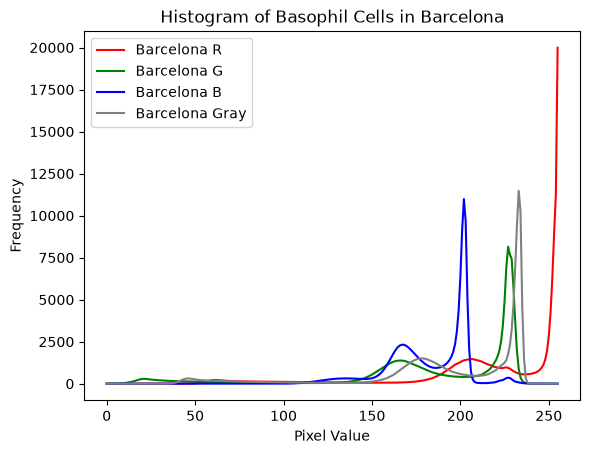

In [89]:
plt.plot(
    range(256),
    hists.loc[("BARCELONA", "basophil"), [f"R{i}" for i in range(256)]],
    label="Barcelona R",
    color="r",
)
plt.plot(
    range(256),
    hists.loc[("BARCELONA", "basophil"), [f"G{i}" for i in range(256)]],
    label="Barcelona G",
    color="g",
)
plt.plot(
    range(256),
    hists.loc[("BARCELONA", "basophil"), [f"B{i}" for i in range(256)]],
    label="Barcelona B",
    color="b",
)
plt.plot(
    range(256),
    hists.loc[("BARCELONA", "basophil"), [f"Gray{i}" for i in range(256)]],
    label="Barcelona Gray",
    color="gray",
)
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Histogram of Basophil Cells in Barcelona")
plt.legend()
plt.show()

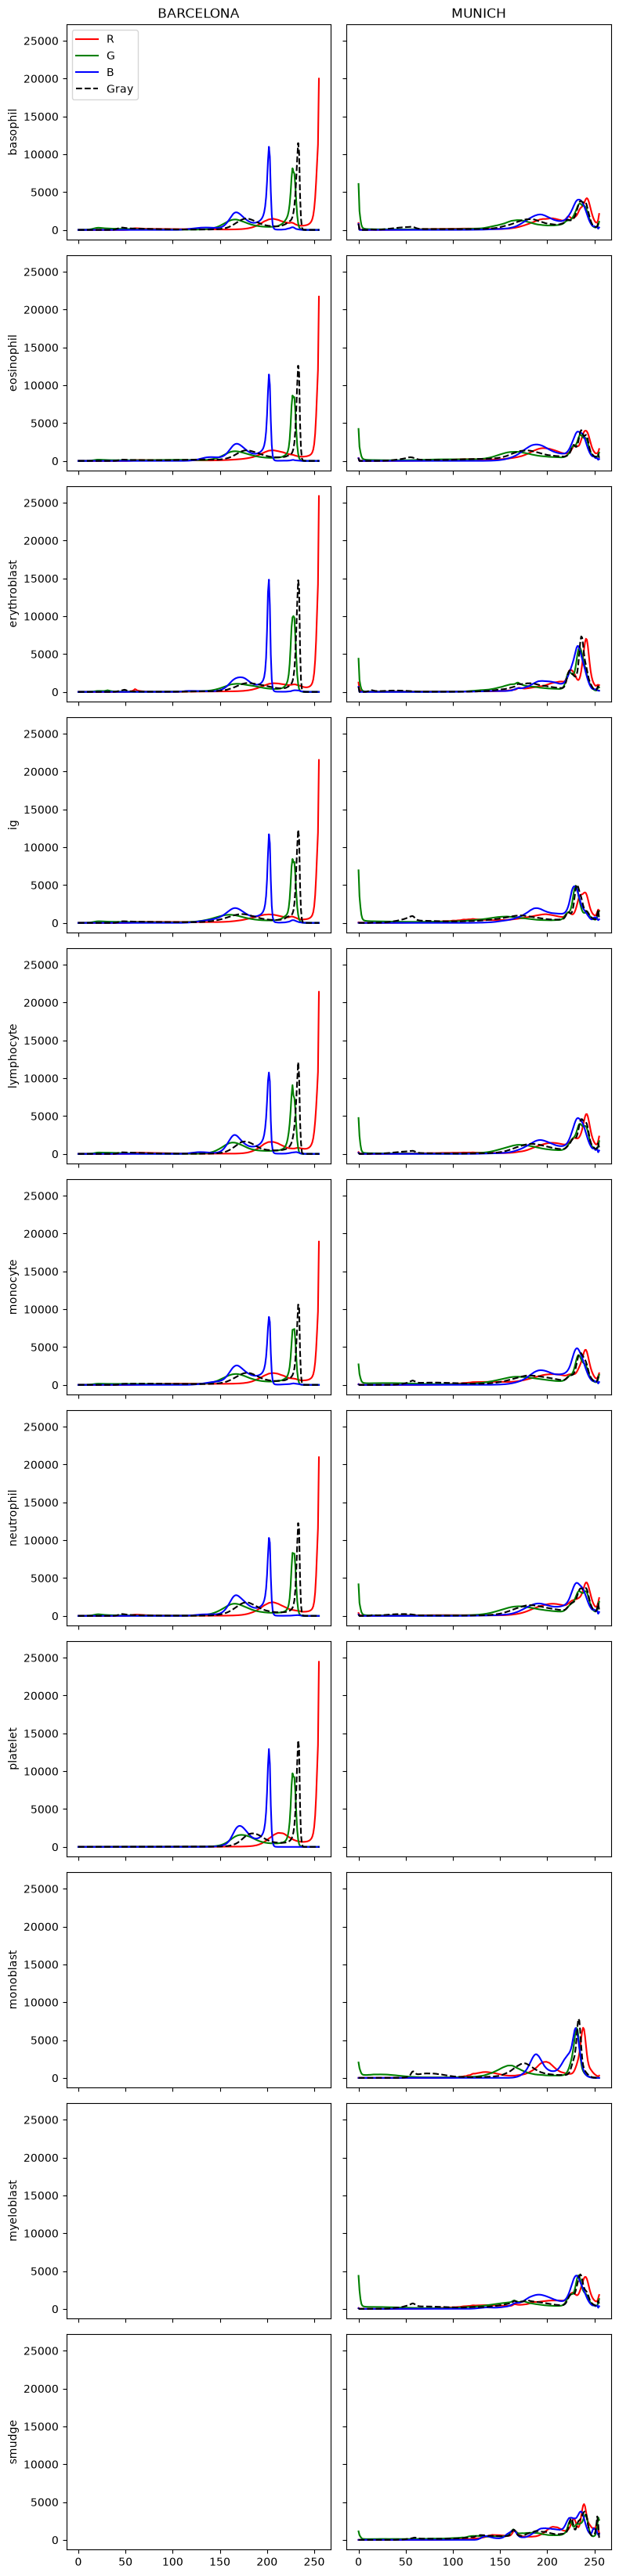

In [ ]:
r_cols = [f"R{i}" for i in range(256)]
g_cols = [f"G{i}" for i in range(256)]
b_cols = [f"B{i}" for i in range(256)]
gray_cols = [f"Gray{i}" for i in range(256)]

datasets = hists.index.get_level_values("dataset").unique()
types = hists.index.get_level_values("type").unique()

fig, axes = plt.subplots(
    len(types),
    len(datasets),
    figsize=(4 * len(datasets), 3 * len(types)),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for i, typ in enumerate(types):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]
        if i == 0:
            ax.set_title(dataset)
        if j == 0:
            ax.set_ylabel(typ)
        if (dataset, typ) not in hists.index:
            # ax.axis("off")
            continue
        row = hists.loc[(dataset, typ)]
        ax.plot(row[r_cols].values, color="red", label="R")
        ax.plot(row[g_cols].values, color="green", label="G")
        ax.plot(row[b_cols].values, color="blue", label="B")
        ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")


axes[0, 0].legend()
plt.tight_layout()
plt.show()


In [ ]:
img_barcelona = Image.open(df[(df.dataset == "BARCELONA") & (df.type == "basophil")].iloc[0].path)
img_munich = Image.open(df[(df.dataset == "MUNICH") & (df.type == "basophil")].iloc[0].path)

In [ ]:
img_barcelona.show("barcelona")
# img_munich.show('munich')

In [ ]:
img_munich.show("munich")

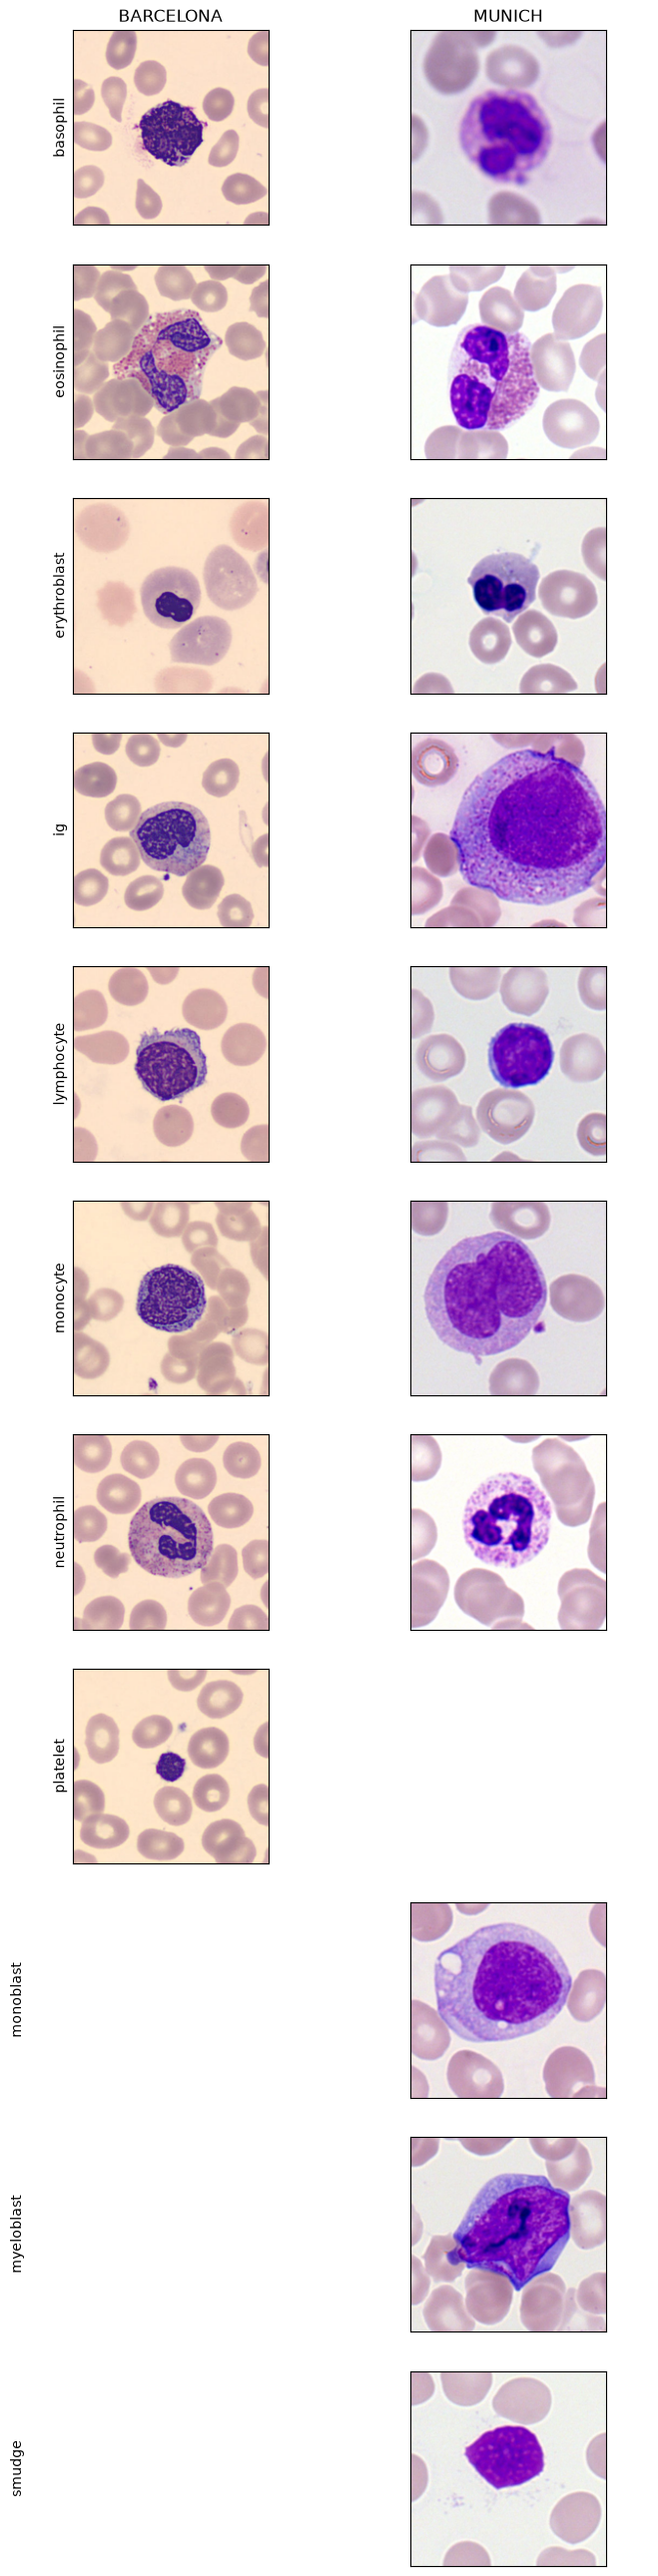

In [ ]:
fig, axes = plt.subplots(
    len(types),
    len(datasets),
    figsize=(4 * len(datasets), 3 * len(types)),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for i, typ in enumerate(types):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]
        ax.set(xticks=[], yticks=[])
        if i == 0:
            ax.set_title(dataset)
        if j == 0:
            ax.set_ylabel(typ)

        imgs = df[(df.dataset == dataset) & (df.type == typ)]
        if len(imgs) == 0:
            plt.setp(ax.spines.values(), visible=False)
            continue
        ax.imshow(Image.open(imgs.sample(n=1, random_state=42).iloc[0].path).resize((200, 200)))
fig.savefig("blood_cells_samples.png", dpi=300, bbox_inches="tight")


In [ ]:
def weighted_mean_std_agg(hist_cols, df):
    vals = np.arange(256)
    counts = df[hist_cols].values.sum(axis=0)
    total = counts.sum()
    mean = (counts * vals).sum() / total
    var = (counts * (vals - mean) ** 2).sum() / total
    return mean, np.sqrt(var)


stats = {}
for dataset, sub in full_df.groupby("dataset"):
    stats[dataset] = {
        ch: weighted_mean_std_agg([f"{ch}{i}" for i in range(256)], sub) for ch in ["R", "G", "B"]
    }
# stats['BARCELONA']['R'] -> (mean_scalaire, std_scalaire) pour tout le dataset


def normalize_channel(channel_array, src_mean, src_std, tgt_mean, tgt_std):
    out = (channel_array.astype(np.float32) - src_mean) / (src_std + 1e-6)
    out = out * tgt_std + tgt_mean
    return np.clip(out, 0, 255).astype(np.uint8)

In [128]:
stats["BARCELONA"]["R"][0]

np.float64(222.82267097394785)

In [147]:
i = 0
row = full_df.iloc[i]
img_pil = Image.open(row.path).convert("RGB")
img_shape = img_pil.size + (3,)
img = np.array(img_pil.get_flattened_data())
print(img.shape, img_shape)
map_channel = {"R": 0, "G": 1, "B": 2}

target_stats = {
    ch: weighted_mean_std_agg([f"{ch}{i}" for i in range(256)], full_df) for ch in ["R", "G", "B"]
}
for ch_name, ch_idx in map_channel.items():
    src_mean, src_std = stats[row.dataset][ch_name]
    tgt_mean, tgt_std = target_stats[ch_name]
    channel_array = np.array([pixel[ch_idx] for pixel in img])
    img[:, ch_idx] = normalize_channel(channel_array, src_mean, src_std, tgt_mean, tgt_std)


(160000, 3) (400, 400, 3)


In [ ]:
Image.fromarray(img.reshape(img_shape).astype(np.uint8)).show("normalized")
# img_pil.show('normalized')
# img.max(), img.min(), img.dtype

In [ ]:
def normalize_image(img: Image, stats: dict, target_stats: dict):
    img_shape = img.size[::-1] + (3,)
    img_data = np.array(img.convert("RGB").get_flattened_data())

    map_channel = {"R": 0, "G": 1, "B": 2}
    for ch_name, ch_idx in map_channel.items():
        src_mean, src_std = stats[ch_name]
        tgt_mean, tgt_std = target_stats[ch_name]
        channel_array = np.array([pixel[ch_idx] for pixel in img_data])
        img_data[:, ch_idx] = normalize_channel(channel_array, src_mean, src_std, tgt_mean, tgt_std)
    return Image.fromarray(img_data.reshape(img_shape).astype(np.uint8))

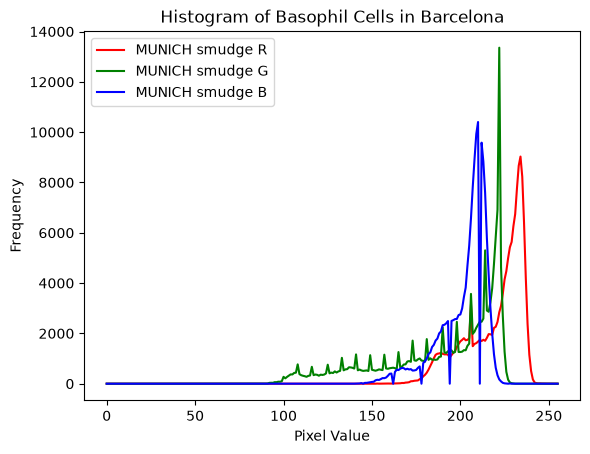

In [154]:
img_norm = normalize_image(img_pil, stats[row.dataset], target_stats)
img_hist = np.array(img_norm.histogram())
plt.plot(range(256), img_hist[:256], label=f"{row.dataset} {row.type} R", color="r")
plt.plot(range(256), img_hist[256:512], label=f"{row.dataset} {row.type} G", color="g")
plt.plot(range(256), img_hist[512:], label=f"{row.dataset} {row.type} B", color="b")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Histogram of Basophil Cells in Barcelona")
plt.legend()
plt.show()

In [ ]:
colors_norm = np.zeros((len(df), 768))
gray_norm = np.zeros((len(df), 256))

for i, row in enumerate(df.itertuples()):
    img = Image.open(row.path)
    img = normalize_image(img, stats[row.dataset], target_stats)
    colors_norm[i] = np.array(img.histogram())
    gray_norm[i] = np.array(img.convert("L").histogram())


In [ ]:
colors_norm_df = pd.DataFrame(
    colors_norm,
    columns=[f"R{i}" for i in range(256)]
    + [f"G{i}" for i in range(256)]
    + [f"B{i}" for i in range(256)],
)
gray_norm_df = pd.DataFrame(gray_norm, columns=[f"Gray{i}" for i in range(256)])
full_norm_df = pd.concat([df, colors_norm_df, gray_norm_df], axis=1)


In [ ]:
hists_norm = (
    full_norm_df.drop(["path", "original_type", "format", "mode", "size_x", "size_y"], axis=1)
    .groupby(["dataset", "type"])
    .mean()
)


In [182]:
full_norm_df.to_csv(DATA_PATH / "blood_cells_data_with_histograms_norm.csv", index=False)
hists_norm.to_csv(DATA_PATH / "blood_cells_histograms_norm.csv")

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_74111/640585415.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show();


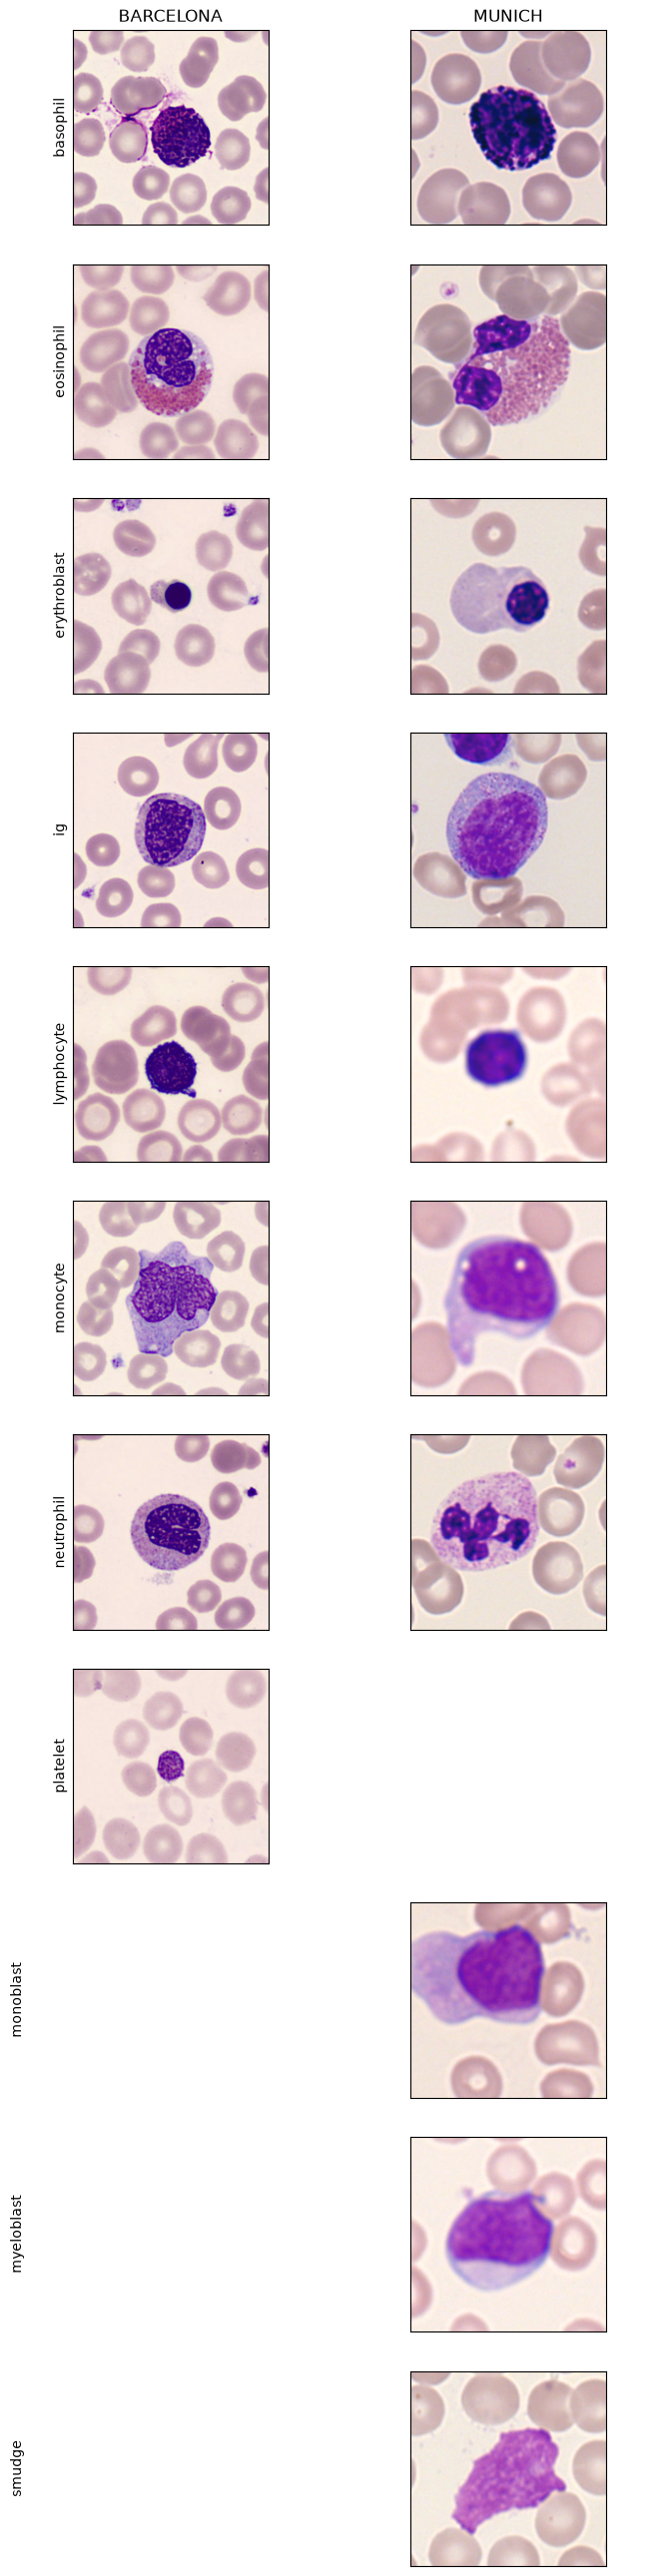

In [183]:
fig, axes = plt.subplots(
    len(types),
    len(datasets),
    figsize=(4 * len(datasets), 3 * len(types)),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for i, typ in enumerate(types):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]
        ax.set(xticks=[], yticks=[])
        if i == 0:
            ax.set_title(dataset)
        if j == 0:
            ax.set_ylabel(typ)

        imgs = df[(df.dataset == dataset) & (df.type == typ)]
        if len(imgs) == 0:
            plt.setp(ax.spines.values(), visible=False)
            continue
        img = normalize_image(
            Image.open(imgs.sample(n=1, random_state=42).iloc[0].path), stats[dataset], target_stats
        )
        ax.imshow(img.resize((200, 200)))
# fig.savefig("blood_cells_samples.png", dpi=300, bbox_inches='tight')
fig.show();

In [175]:
img_barcelona = Image.open(df[df.dataset == "BARCELONA"].iloc[0].path)
img_bar_norm = normalize_image(img_barcelona, stats["BARCELONA"], target_stats)
img_bar_norm.show("normalized barcelona")
img_barcelona.show("original barcelona")

(360, 363) (363, 360, 3)


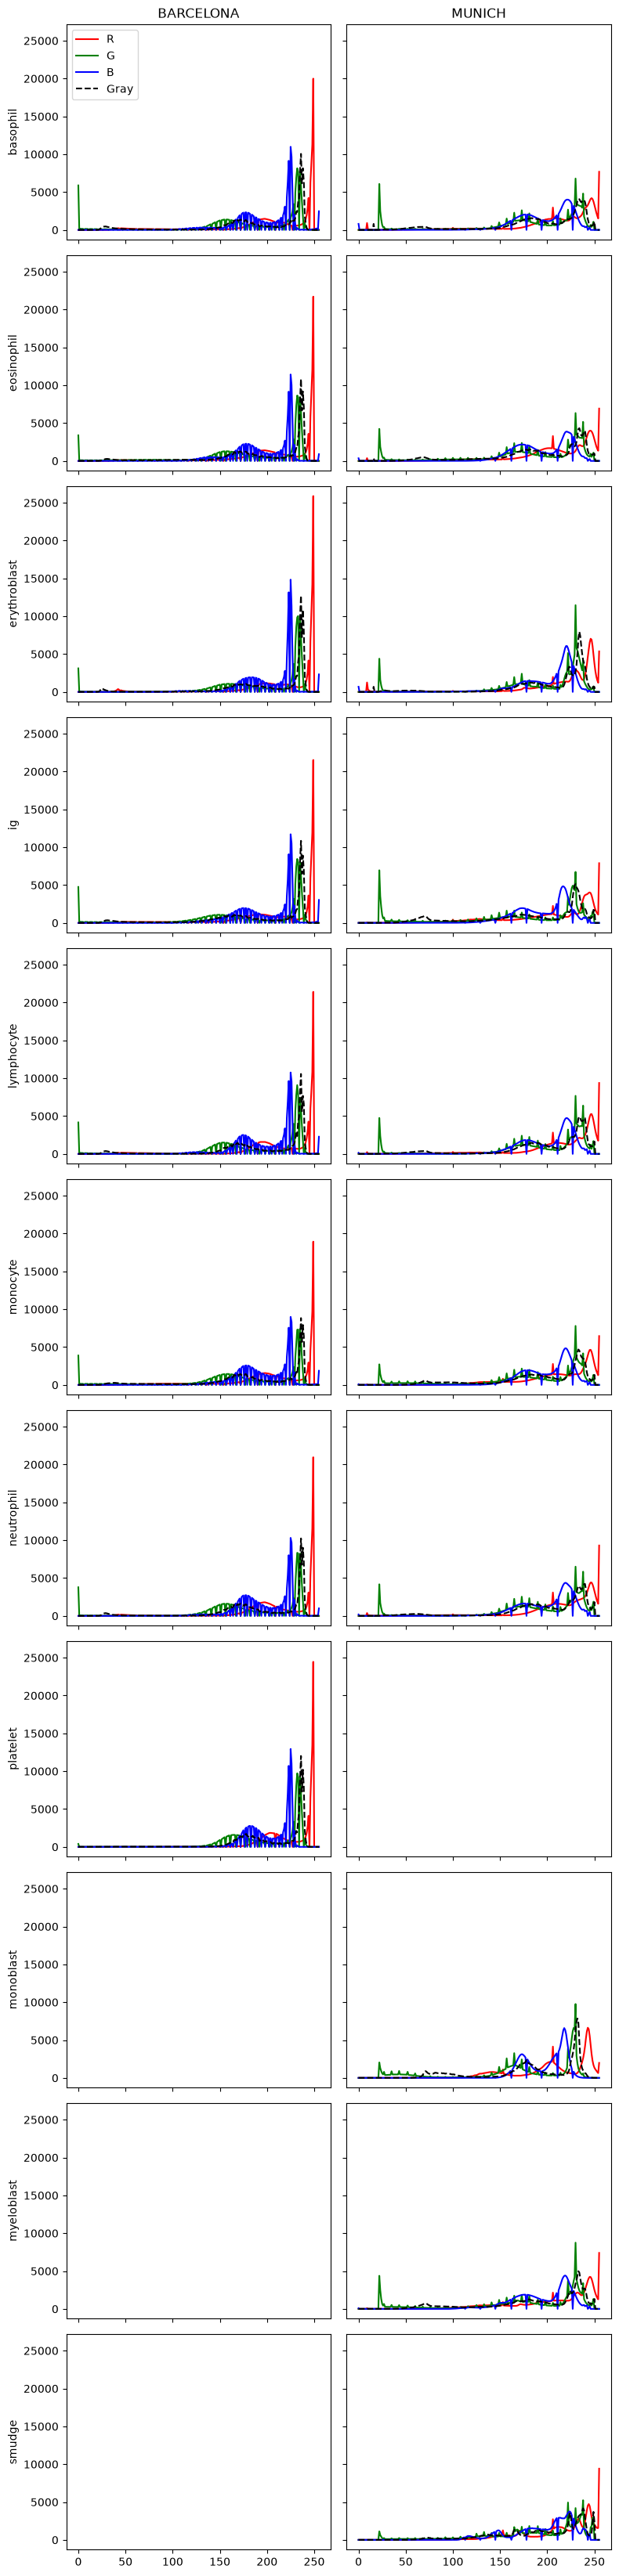

In [ ]:
r_cols = [f"R{i}" for i in range(256)]
g_cols = [f"G{i}" for i in range(256)]
b_cols = [f"B{i}" for i in range(256)]
gray_cols = [f"Gray{i}" for i in range(256)]

datasets = hists_norm.index.get_level_values("dataset").unique()
types = hists_norm.index.get_level_values("type").unique()

fig, axes = plt.subplots(
    len(types),
    len(datasets),
    figsize=(4 * len(datasets), 3 * len(types)),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for i, typ in enumerate(types):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]
        if i == 0:
            ax.set_title(dataset)
        if j == 0:
            ax.set_ylabel(typ)
        if (dataset, typ) not in hists_norm.index:
            # ax.axis("off")
            continue
        row = hists_norm.loc[(dataset, typ)]
        ax.plot(row[r_cols].values, color="red", label="R")
        ax.plot(row[g_cols].values, color="green", label="G")
        ax.plot(row[b_cols].values, color="blue", label="B")
        ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")


axes[0, 0].legend()
plt.tight_layout()
plt.show()

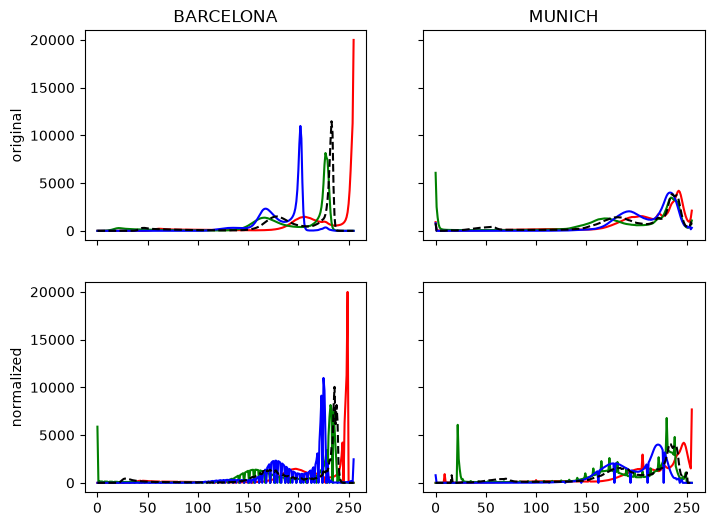

In [204]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True, squeeze=False)
ax = axes[0, 0]
ax.set_title("BARCELONA")
ax.set_ylabel("original")

row = hists.loc[("BARCELONA", "basophil")]
ax.plot(row[r_cols].values, color="red", label="R")
ax.plot(row[g_cols].values, color="green", label="G")
ax.plot(row[b_cols].values, color="blue", label="B")
ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")

ax = axes[0, 1]
ax.set_title("MUNICH")

row = hists.loc[("MUNICH", "basophil")]
ax.plot(row[r_cols].values, color="red", label="R")
ax.plot(row[g_cols].values, color="green", label="G")
ax.plot(row[b_cols].values, color="blue", label="B")
ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")

ax = axes[1, 0]
ax.set_ylabel("normalized")

row = hists_norm.loc[("BARCELONA", "basophil")]
ax.plot(row[r_cols].values, color="red", label="R")
ax.plot(row[g_cols].values, color="green", label="G")
ax.plot(row[b_cols].values, color="blue", label="B")
ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")

ax = axes[1, 1]
row = hists_norm.loc[("MUNICH", "basophil")]
ax.plot(row[r_cols].values, color="red", label="R")
ax.plot(row[g_cols].values, color="green", label="G")
ax.plot(row[b_cols].values, color="blue", label="B")
ax.plot(row[gray_cols].values, color="black", label="Gray", linestyle="--")

<Axes: >

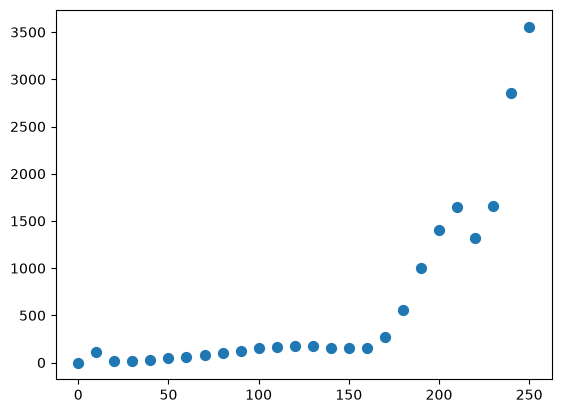

In [217]:
sns.regplot(
    x=np.array(range(256)),
    y=row[r_cols].values,
    ci=None,
    truncate=False,
    fit_reg=False,
    x_bins=range(0, 260, 10),
)
sns.lineplot()


In [211]:
import importlib

importlib.reload(sns)

<module 'seaborn' from '/Users/romain/Projects/Liora/Projet/.venv/lib/python3.14/site-packages/seaborn/__init__.py'>

In [ ]:
gray_cols = [f"Gray{i}" for i in range(256)]
vals = np.arange(256)


def brightness_contrast(row):
    counts = row[gray_cols].values.astype(float)
    total = counts.sum()
    mean = (counts * vals).sum() / total
    std = np.sqrt((counts * (vals - mean) ** 2).sum() / total)
    return pd.Series({"brightness": mean, "contrast": std})


In [46]:
full_df[["brightness", "contrast"]] = full_df.apply(brightness_contrast, axis=1)
full_norm_df[["brightness", "contrast"]] = full_norm_df.apply(brightness_contrast, axis=1)
full_df.columns

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_75028/891936354.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  full_df[['brightness', 'contrast']] = full_df.apply(brightness_contrast, axis=1)
/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_75028/891936354.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  full_norm_df[['brightness', 'contrast']] = full_norm_df.apply(brightness_contrast, axis=1)


Index(['dataset', 'path', 'original_type', 'format', 'size_x', 'size_y',
       'mode', 'type', 'R0', 'R1',
       ...
       'Gray248', 'Gray249', 'Gray250', 'Gray251', 'Gray252', 'Gray253',
       'Gray254', 'Gray255', 'brightness', 'contrast'],
      dtype='str', length=1034)

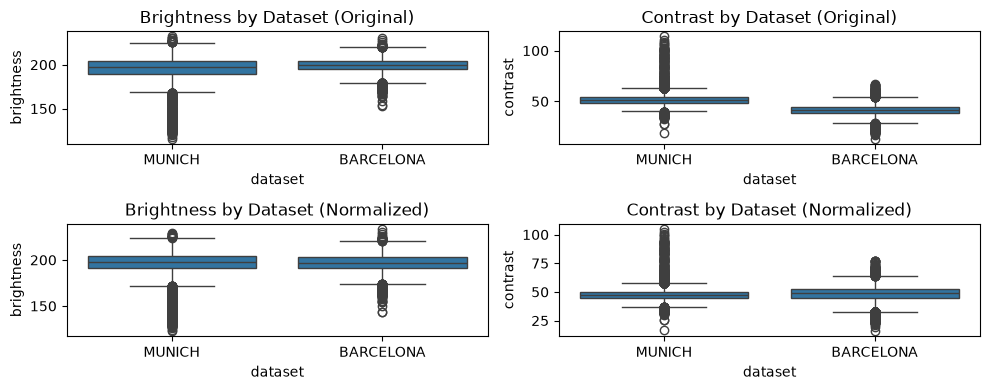

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(10, 4))
sns.boxplot(data=full_df, x="dataset", y="brightness", ax=axes[0, 0])
axes[0, 0].set_title("Brightness by Dataset (Original)")
sns.boxplot(data=full_df, x="dataset", y="contrast", ax=axes[0, 1])
axes[0, 1].set_title("Contrast by Dataset (Original)")
sns.boxplot(data=full_norm_df, x="dataset", y="brightness", ax=axes[1, 0])
axes[1, 0].set_title("Brightness by Dataset (Normalized)")
sns.boxplot(data=full_norm_df, x="dataset", y="contrast", ax=axes[1, 1])
axes[1, 1].set_title("Contrast by Dataset (Normalized)")
plt.tight_layout()
plt.show()

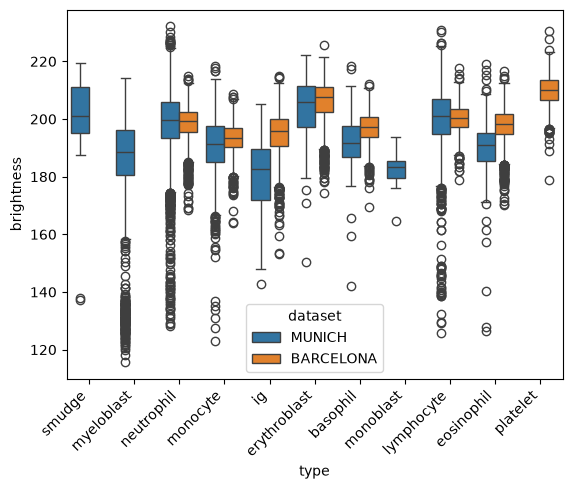

In [229]:
sns.boxplot(data=full_df, hue="dataset", x="type", y="brightness")
plt.xticks(rotation=45, ha="right");


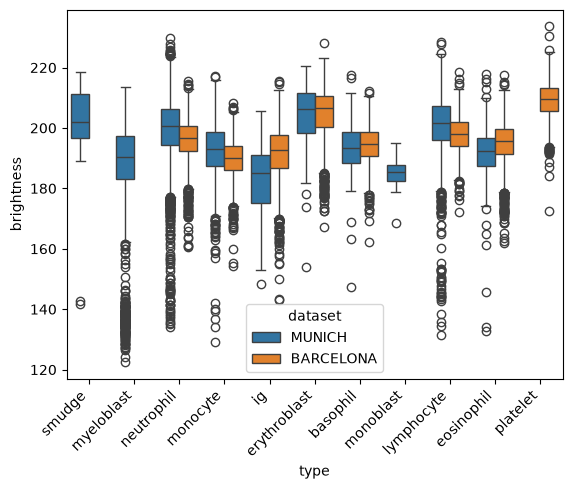

In [230]:
sns.boxplot(data=full_norm_df, hue="dataset", x="type", y="brightness")
plt.xticks(rotation=45, ha="right");


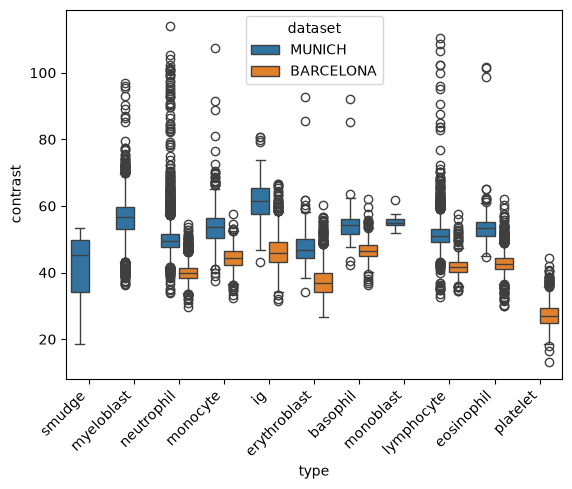

In [231]:
sns.boxplot(data=full_df, hue="dataset", x="type", y="contrast")
plt.xticks(rotation=45, ha="right");


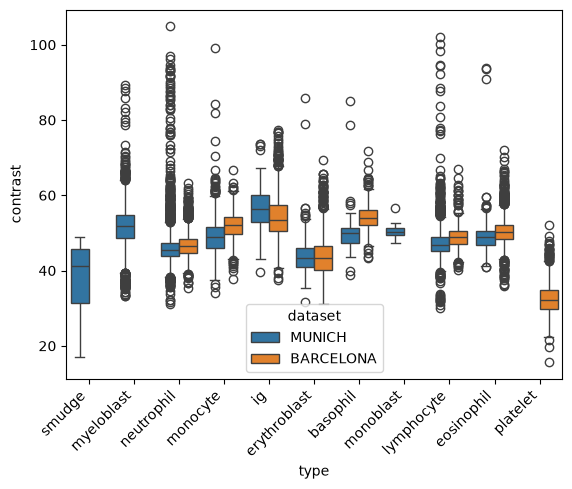

In [232]:
sns.boxplot(data=full_norm_df, hue="dataset", x="type", y="contrast")
plt.xticks(rotation=45, ha="right");


In [ ]:
from concurrent.futures import ThreadPoolExecutor

import cv2

SIZE = 100
SAMPLE_SIZE = 1000


def _load_one(item, size=SIZE):
    i, path = item
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return i, cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


df_sample = full_df.sample(SAMPLE_SIZE)
images = np.empty((len(df_sample), SIZE, SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(max_workers=8) as ex:
    for i, img in ex.map(_load_one, enumerate(df_sample["path"])):
        images[i] = img

In [ ]:
images = images.reshape(len(images), -1).astype(np.float32) / 255.0


In [53]:
from sklearn.decomposition import IncrementalPCA

pca = IncrementalPCA(n_components=2)
data_2D = pca.fit_transform(images)
pca.explained_variance_ratio_

array([0.11402031, 0.07617604])

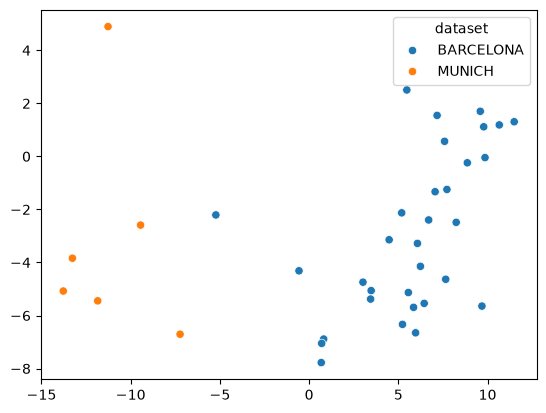

In [35]:
import seaborn as sns

mask = df_sample.type == "basophil"
sns.scatterplot(x=data_2D[mask, 0], y=data_2D[mask, 1], hue=df_sample.loc[mask, "dataset"]);


In [50]:
import plotly.express as px

mask = df_sample.dataset.notnull()
fig = px.scatter_3d(
    x=data_3D[mask, 0], y=data_3D[mask, 1], z=data_3D[mask, 2], color=df_sample[mask].dataset
)
fig.update_layout(title="3D PCA of Blood Cell Images")
fig.show()

In [ ]:
df_norm_sample = full_norm_df.sample(SAMPLE_SIZE)
images_norm = np.empty((len(df_norm_sample), SIZE, SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(max_workers=8) as ex:
    for i, img in ex.map(_load_one, enumerate(df_norm_sample["path"])):
        images_norm[i] = img

images_norm = images_norm.reshape(len(images_norm), -1).astype(np.float32) / 255.0

pca_norm = IncrementalPCA(n_components=2)
data_2D_norm = pca_norm.fit_transform(images_norm)

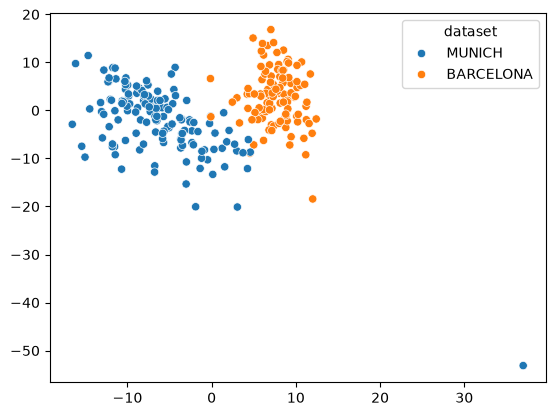

In [28]:
sns.scatterplot(x=data_2D_norm[:, 0], y=data_2D_norm[:, 1], hue=df_norm_sample.dataset);


In [69]:
img = cv2.imread(DATA_PATH / "PBC_dataset_normal_DIB" / "basophil" / "BA_47.jpg", cv2.IMREAD_COLOR)
hist = cv2.calcHist([img], [0, 1, 2], None, [256, 256, 256], [0, 256, 0, 256, 0, 256])
hist.ndim

3

In [71]:
ddff = pd.DataFrame({"r": [1, 2, 3], "g": [4, 5, 6], "b": [7, 8, 9]})
ddff.apply(lambda row: ((row["r"] + row["g"] + row["b"]) / 3, 2), axis=1)

0    (4.0, 2)
1    (5.0, 2)
2    (6.0, 2)
dtype: object

In [ ]:
sampled_df = full_df.groupby("dataset").apply(lambda x: x.sample(n=200))

In [ ]:
import sys

sys.path.insert(0, "../src")

In [ ]:
from features.classify_datasets import MacenkoNormalize

norm = MacenkoNormalize(
    reference_image_path="/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PKG-AML-Cytomorphology_LMU/NGS/NGS_0117.tiff"
)


In [85]:
img_barcelona = Image.open(full_df[full_df.dataset == "BARCELONA"].iloc[0].path)
img_norm = norm(img_barcelona)
img_barcelona.show("original barcelona")
img_norm.show("normalized barcelona")

In [87]:
norm_barcelona = MacenkoNormalize(
    reference_image_path="/Users/romain/Projects/Liora/Projet/jul26_bds_blood_cells/data/PBC_dataset_normal_DIB/neutrophil/BNE_62365.jpg"
)
img_munich = Image.open(full_df[full_df.dataset == "MUNICH"].iloc[1].path)
img_munich_norm = norm_barcelona(img_munich)
img_munich.show("original munich")
img_munich_norm.show("normalized munich")

In [89]:
full_df.groupby(["type", "dataset"]).size()

type          dataset  
basophil      BARCELONA    1218
              MUNICH         79
eosinophil    BARCELONA    3117
              MUNICH        424
erythroblast  BARCELONA    1551
              MUNICH         78
ig            BARCELONA    2895
              MUNICH        145
lymphocyte    BARCELONA    1214
              MUNICH       3948
monoblast     MUNICH         26
monocyte      BARCELONA    1420
              MUNICH       1789
myeloblast    MUNICH       3268
neutrophil    BARCELONA    3329
              MUNICH       8593
platelet      BARCELONA    2348
smudge        MUNICH         15
dtype: int64

In [90]:
full_df[full_df.dataset == "BARCELONA"].count()

dataset          17092
path             17092
original_type    17092
format           17092
size_x           17092
                 ...  
Gray251          17092
Gray252          17092
Gray253          17092
Gray254          17092
Gray255          17092
Length: 1032, dtype: int64

In [91]:
full_df.columns

Index(['dataset', 'path', 'original_type', 'format', 'size_x', 'size_y',
       'mode', 'type', 'R0', 'R1',
       ...
       'Gray246', 'Gray247', 'Gray248', 'Gray249', 'Gray250', 'Gray251',
       'Gray252', 'Gray253', 'Gray254', 'Gray255'],
      dtype='str', length=1032)

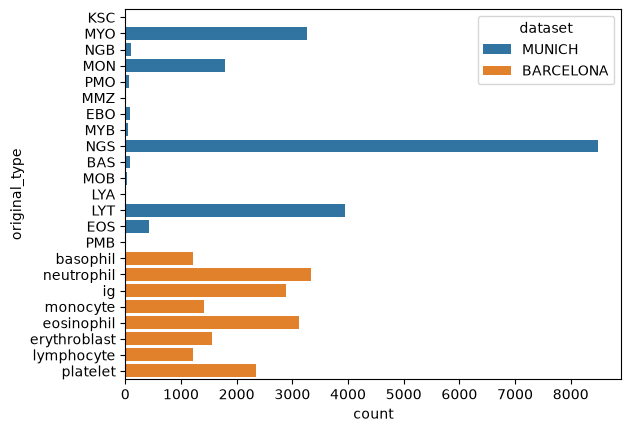

In [94]:
sns.countplot(data=full_df, y="original_type", hue="dataset");

In [95]:
BARCELONA_DICT = {
    "BA": "BAS",
    "EO": "EOS",
    "ERB": "EBO",
    "MMY": "MMZ",
    "MY": "MYB",
    "PMY": "PMO",
    "LY": "LY",
    "MO": "MON",
    "BNE": "NGB",
    "SNE": "NGS",
    "PLATELET": "PLT",
}
MUNICH_DICT = {
    "BAS": "BAS",
    "EBO": "EBO",
    "EOS": "EOS",
    "LYA": "LY",
    "LYT": "LY",
    "MMZ": "MMZ",
    "MON": "MON",
    "MYB": "MYB",
    "MYO": "MYO",
    "NGB": "NGB",
    "NGS": "NGS",
    "PMB": "PMO",
    "PMO": "PMO",
}
MAPPING_DICT = {"BARCELONA": BARCELONA_DICT, "MUNICH": MUNICH_DICT}

In [96]:
full_df["new_type"] = full_df.apply(
    lambda row: MAPPING_DICT[row.dataset].get(row.original_type, np.nan), axis=1
)

/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_75028/2786900993.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  full_df["new_type"] = full_df.apply(


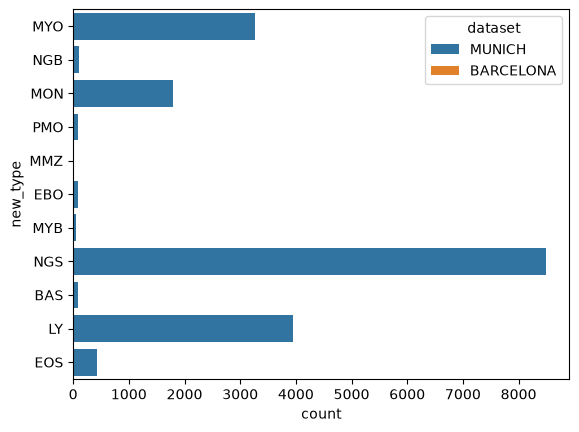

In [97]:
sns.countplot(data=full_df, y="new_type", hue="dataset");

In [100]:
full_df[full_df.dataset == "BARCELONA"].iloc[0].original_type

'basophil'

In [5]:
import pandas as pd

In [6]:
def get_images(data_dir: str, dataset_name: str) -> list[tuple[str, str, str]]:
    """Renvoie une liste de tuple contenant les chemins vers les images, le dataset et le type originel."""
    data_path = Path(data_dir)
    image_paths = (
        list(data_path.glob("**/*.jpg"))
        + list(data_path.glob("**/*.png"))
        + list(data_path.glob("**/*.tiff"))
    )
    labels = [p.stem.split("_")[0] for p in image_paths]
    print(set(labels))
    return [(str(p), dataset_name, label) for p, label in zip(image_paths, labels)]


In [7]:
barcelona_df = pd.DataFrame(
    get_images(DATA_PATH / BARCELONA_DATA_PATH, "BARCELONA"),
    columns=["path", "dataset", "original_type"],
)
barcelona_df.head()

NameError: name 'DATA_PATH' is not defined

In [ ]:
barcelona_df["type"] = barcelona_df.apply(
    lambda row: BARCELONA_DICT.get(row["original_type"], np.nan), axis=1
)
barcelona_df.head()

,path,dataset,original_type,type
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,BARCELONA,BA,BAS
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,BARCELONA,BA,BAS
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,BARCELONA,BA,BAS
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,BARCELONA,BA,BAS
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,BARCELONA,BA,BAS


In [ ]:
munich_df = pd.DataFrame(
    get_images(DATA_PATH / MUNICH_DATA_PATH, "MUNICH"), columns=["path", "dataset", "original_type"]
)
munich_df["type"] = munich_df.apply(
    lambda row: MUNICH_DICT.get(row["original_type"], np.nan), axis=1
)

munich_df.head()

{'MOB', 'MON', 'KSC', 'PMO', 'NGB', 'LYA', 'NGS', 'BAS', 'LYT', 'MYB', 'EOS', 'EBO', 'MMZ', 'MYO', 'PMB'}


,path,dataset,original_type,type
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN


In [111]:
new_df = pd.concat([munich_df, barcelona_df], ignore_index=True)
new_df.head(), new_df.tail()

(                                                path dataset original_type  \
 0  /Users/romain/Projects/Liora/Projet/jul26_bds_...  MUNICH           KSC   
 1  /Users/romain/Projects/Liora/Projet/jul26_bds_...  MUNICH           KSC   
 2  /Users/romain/Projects/Liora/Projet/jul26_bds_...  MUNICH           KSC   
 3  /Users/romain/Projects/Liora/Projet/jul26_bds_...  MUNICH           KSC   
 4  /Users/romain/Projects/Liora/Projet/jul26_bds_...  MUNICH           KSC   
 
   type  
 0  NaN  
 1  NaN  
 2  NaN  
 3  NaN  
 4  NaN  ,
                                                     path    dataset  \
 35452  /Users/romain/Projects/Liora/Projet/jul26_bds_...  BARCELONA   
 35453  /Users/romain/Projects/Liora/Projet/jul26_bds_...  BARCELONA   
 35454  /Users/romain/Projects/Liora/Projet/jul26_bds_...  BARCELONA   
 35455  /Users/romain/Projects/Liora/Projet/jul26_bds_...  BARCELONA   
 35456  /Users/romain/Projects/Liora/Projet/jul26_bds_...  BARCELONA   
 
       original_type type  
 

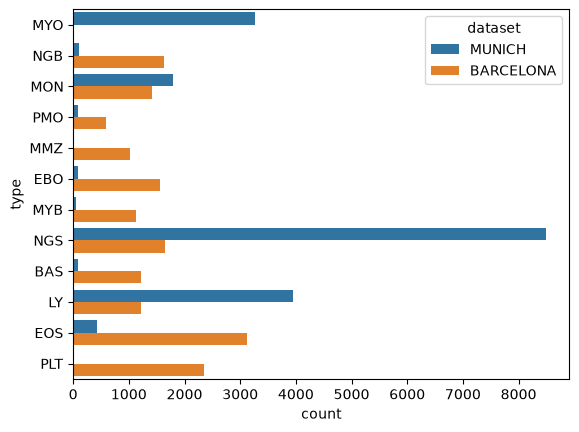

In [112]:
sns.countplot(data=new_df, y="type", hue="dataset");

In [113]:
new_df[new_df.original_type == "PMB"].count()

path             18
dataset          18
original_type    18
type             18
dtype: int64

In [114]:
new_df.original_type.value_counts()

original_type
NGS           8484
LYT           3937
MYO           3268
EO            3117
PLATELET      2348
MON           1789
SNE           1646
BNE           1633
ERB           1551
MO            1420
BA            1218
LY            1214
MY            1137
MMY           1015
PMY            592
EOS            424
IG             151
NGB            109
BAS             79
EBO             78
PMO             70
NEUTROPHIL      50
MYB             42
MOB             26
PMB             18
KSC             15
MMZ             15
LYA             11
Name: count, dtype: int64

In [115]:
MAPPING_DICT

{'BARCELONA': {'BA': 'BAS',
  'EO': 'EOS',
  'ERB': 'EBO',
  'MMY': 'MMZ',
  'MY': 'MYB',
  'PMY': 'PMO',
  'LY': 'LY',
  'MO': 'MON',
  'BNE': 'NGB',
  'SNE': 'NGS',
  'PLATELET': 'PLT'},
 'MUNICH': {'BAS': 'BAS',
  'EBO': 'EBO',
  'EOS': 'EOS',
  'LYA': 'LY',
  'LYT': 'LY',
  'MMZ': 'MMZ',
  'MON': 'MON',
  'MYB': 'MYB',
  'MYO': 'MYO',
  'NGB': 'NGB',
  'NGS': 'NGS',
  'PMB': 'PMO',
  'PMO': 'PMO'}}

In [ ]:
for t in new_df.original_type.unique():
    if not (t in BARCELONA_DICT or t in MUNICH_DICT):
        print(t)

KSC
MOB
NEUTROPHIL
IG


In [ ]:
abbrev_to_full = {
    "MYO": "Myeloblast",
    "NGB": "Neutrophil (band)",
    "MON": "Monocyte",
    "PMO": "Promyelocyte",
    "MMZ": "Metamyelocyte",
    "EBO": "Erythroblast",
    "MYB": "Myelocyte",
    "NGS": "Neutrophil (segmented)",
    "BAS": "Basophil",
    "LY": "Lymphocyte",  # regroupement présumé de LYA (atypical) + LYT (typical)
    "EOS": "Eosinophil",
    "PLT": "Platelet",  # non présent dans ta légende, sens standard
}
new_df["full_type"] = new_df.apply(lambda row: abbrev_to_full.get(row.type, np.nan), axis=1)
new_df.head()

,path,dataset,original_type,type,full_type
0,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN,NaN
1,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN,NaN
2,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN,NaN
3,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN,NaN
4,/Users/romain/Projects/Liora/Projet/jul26_bds_...,MUNICH,KSC,NaN,NaN


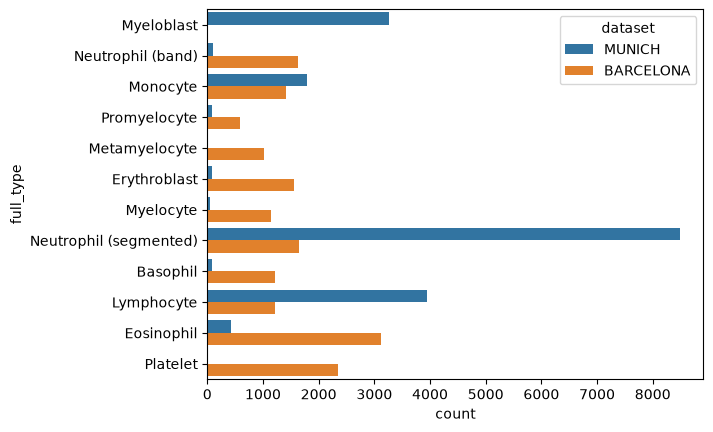

In [120]:
sns.countplot(data=new_df, y="full_type", hue="dataset");

In [ ]:
new_df.groupby(["dataset", "full_type"]).count()

NameError: name 'new_df' is not defined